<a href="https://colab.research.google.com/github/ancestor9/2026_Fall_AI-Workflow/blob/main/CH4_Using_LangGraph_to_Add_Memory_to_Your_Chatbot_ipynb.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import os
from google.colab import userdata

# Groq API 키 설정
YOUR_API_KEY = userdata.get('groq')
os.environ["GROQ_API_KEY"] = YOUR_API_KEY

In [2]:
!pip install -qU langchain-groq

In [4]:
# @title **LLM에게 과거 대화 내역(Context)을 전달하여 문맥을 이해하게 만드는 원리**
from langchain_core.prompts import ChatPromptTemplate
from langchain_groq import ChatGroq

prompt = ChatPromptTemplate.from_messages([
    ("system", "You are a helpful assistant. Answer all questions to the best of your ability."),
    ("placeholder", "{messages}"), # 단순 텍스트가 아닌 대화 기록(히스토리)을 프롬프트에 동적으로 삽입할 때 사용
])

model = ChatGroq(model="openai/gpt-oss-20b")

chain = prompt | model

# 3개의 연속된 대화 내역을 리스트로 묶어 전달
response = chain.invoke({
    "messages": [
        ("human", "Translate this sentence from English to German: I love programming."),
        ("ai", "Ich liebe das Programmieren."), # Mocking(의도적인 가짜 데이터 주입)
        ("human", "What did you just say?"),
    ],
})

print(response.content)

I translated the sentence into German: **“Ich liebe das Programmieren.”**


In [6]:
messages = [
    ("human", "Translate this sentence from English to German: I love programming."),
    ("ai", "Ich liebe das Programmieren."),
    ("human", "What did you just say?"),
]

response = chain.invoke({"messages": messages})
print(response.content)

# 모델의 답변을 히스토리에 누적하고, 새 질문을 추가
messages.append(("ai", response.content))
messages.append(("human", "Now translate it to French."))

response = chain.invoke({"messages": messages})
print(response.content)

I said: **“Ich liebe das Programmieren.”**  
That is the German translation of “I love programming.”
The French translation is: **“J'aime programmer.”**


### 두 방식의 차이점

- "ai" 답변이 있을 때 ---> 기억하고 답변: 정말로 과거에 나눈 대화 자체를 회상(Review)하면서, 그 답변(Ich liebe das Programmieren)에 사용된 문법이나 단어(명사형/동사형 등)에 대한 깊이 있는 피드백

- "ai" 답변이 없을 때 (현재 코드) ---> 한 번에 읽고 답변: 과거 대화에 대한 피드백을 주는 게 불가능하므로, 유저의 첫 번째 요청을 그 자리에서 수행하며 "당신이 요청한 번역은 이겁니다"라고 답변을 완성

> - "ai" 턴을 빼도 말이 되는 답변이 나오는 이유는, LLM이 앞뒤 문맥을 보고 "대화가 자연스럽게 이어지도록 공백을 메우는 능력"이 매우 뛰어나기 때문


> - 사람의 착각: AI가 첫 번째 질문을 읽고 멈췄다가, 두 번째 질문을 읽고 "어라? 내가 아까 무슨 말을 했더라?" 하고 머릿속 기억을 더듬는다고 생각함.

> - 실제 컴퓨터 내부: LLM은 주석 처리된 리스트를 한 문장으로 이어 붙인 "인간: 독어로 번역해 줘. 인간: 너 방금 뭐라고 했어?"라는 전체 텍스트를 처음부터 끝까지 한 번에(동시에) 읽고 답변 (LLM이 기억하는 방식은 사람의 뇌나 컴퓨터의 하드디스크처럼 "과거의 기억을 저장해 두었다가 꺼내오는 것"은 아님)

In [7]:
# @title 랭체인의 대표적인 내장 메모리 모듈인 ChatMessageHistory

!pip install -qU langchain-community

from langchain_community.chat_message_histories import ChatMessageHistory
from langchain_core.prompts import ChatPromptTemplate
from langchain_groq import ChatGroq

# 1. 프롬프트 템플릿 정의 (placeholder 공간은 그대로 유지)
prompt = ChatPromptTemplate.from_messages([
    ("system", "You are a helpful assistant. Answer all questions to the best of your ability."),
    ("placeholder", "{messages}"),
])

# 2. 언어 모델 설정 (Groq Llama 3.1)
model = ChatGroq(model="openai/gpt-oss-20b")

# 3. 체인 구성
chain = prompt | model

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires requests==2.32.4, but you have requests 2.34.2 which is incompatible.


/tmp/ipykernel_5688/1646097608.py:5: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.chat_message_histories import ChatMessageHistory


In [8]:
# 4. 랑체인 내장 메모리 객체 생성
history = ChatMessageHistory()

# ==========================================
# Turn 1: 첫 번째 대화 (번역 요청)
# ==========================================
print("--- [Turn 1] 유저의 번역 요청 ---")
user_input_1 = "Translate this sentence from English to German: I love programming."

# 유저의 질문을 메모리에 수동(또는 자동 파이프라인)으로 추가
history.add_user_message(user_input_1)

# 메모리에 쌓인 전체 대화 기록을 꺼내서 모델에 전달
response_1 = chain.invoke({"messages": history.messages})
print(f"AI 답변: {response_1.content}\n")

/tmp/ipykernel_5688/3381886280.py:2: LangChainDeprecationWarning: The class `InMemoryChatMessageHistory` was deprecated in LangChain 1.6.4 and will be removed in 2.0.0 See the short-term memory documentation for recommended alternatives: https://docs.langchain.com/oss/python/langchain/short-term-memory
  history = ChatMessageHistory()


--- [Turn 1] 유저의 번역 요청 ---
AI 답변: Ich liebe das Programmieren.



In [9]:
history.messages

[HumanMessage(content='Translate this sentence from English to German: I love programming.', additional_kwargs={}, response_metadata={})]

In [10]:
# AI의 답변도 다음 대화를 위해 메모리에 자동으로 추가
history.add_ai_message(response_1.content)

In [11]:
history.messages

[HumanMessage(content='Translate this sentence from English to German: I love programming.', additional_kwargs={}, response_metadata={}),
 AIMessage(content='Ich liebe das Programmieren.', additional_kwargs={}, response_metadata={}, tool_calls=[], invalid_tool_calls=[])]

In [12]:
# ==========================================
# Turn 2: 두 번째 대화 (이전 맥락 확인 질문)
# ==========================================
print("--- [Turn 2] 유저의 후속 질문 ---")
user_input_2 = "What did you just say?"

# 유저의 두 번째 질문을 다시 메모리에 추가
history.add_user_message(user_input_2)

# 이제 history.messages 안에는 [유저1, AI1, 유저2] 메시지가 모두 누적되어 있음
response_2 = chain.invoke({"messages": history.messages})
print(f"AI 답변:\n{response_2.content}")

--- [Turn 2] 유저의 후속 질문 ---
AI 답변:
I said: **“Ich liebe das Programmieren.”**


In [13]:
history.messages

[HumanMessage(content='Translate this sentence from English to German: I love programming.', additional_kwargs={}, response_metadata={}),
 AIMessage(content='Ich liebe das Programmieren.', additional_kwargs={}, response_metadata={}, tool_calls=[], invalid_tool_calls=[]),
 HumanMessage(content='What did you just say?', additional_kwargs={}, response_metadata={})]

In [14]:
for turn in history.messages:
    print(turn)

content='Translate this sentence from English to German: I love programming.' additional_kwargs={} response_metadata={}
content='Ich liebe das Programmieren.' additional_kwargs={} response_metadata={} tool_calls=[] invalid_tool_calls=[]
content='What did you just say?' additional_kwargs={} response_metadata={}


# **Introducing LangGraph**

LangGraph의 chatbot 노드가 작동하여 hi!라는 질문을 받아 0.037921316초 만에 생각(reasoning_content)을 거쳐 Hello! How can I help you today?라는 AIMessage를 생성해 상태(State)에 추가해 준 결과

- chatbot': 그래프에서 정의한 노드(Node) 이름으로 LangGraph는 스트리밍 출력을 할 때 "어느 노드에서 어떤 작업이 완료되어 상태가 업데이트 되었는 지"를 노드 이름을 키(Key)로 하는 딕셔너리 형태로 반환
- 'messages': chatbot 노드가 반환한 결과가 State의 messages 필드에 성공적으로 반영

> [

>>    {

>>>        'chatbot': {

>>>            'messages': [AIMessage(...)]


>>>        }

>>    }

>]

#### **코드 작동 순서 : START ──▶ chatbot ──▶ END**

- 시작: {"messages": [HumanMessage("hi!")]}가 State에 입력
- START → chatbot: chatbot 노드가 State에서 messages를 꺼내 LLM에 전달
- 노드 실행: LLM의 답변 answer를 {"messages": [answer]}로 반환
- 리듀서 작동: add_messages가 기존 [HumanMessage("hi!")] 뒤에 답변을 붙여 [Human, AI]로 만들기
- chatbot → END: 종료

>> messages 리스트를 직접 만들고 append로 누적하던 방식이, 여기서는 State + 리듀서로 바뀐 것, LLM이 stateless라서 매번 히스토리를 보내야 한다는 원리는 그대로이고, 그 히스토리를 관리해 주는 구조가 LangGraph의 State

>> graph.stream()은 노드가 하나 끝날 때마다 그 노드가 반환한 변경분을 {"chatbot": {"messages": [...]}} 형태로 반환

In [21]:
# @title **Creating a StateGraph**

# Start by creating a StateGraph
from typing import Annotated, TypedDict
from langchain_core.messages import HumanMessage
from langchain_groq import ChatGroq
from langgraph.graph import StateGraph, START, END, add_messages

# 1. 그래프의 상태(State) 및 리듀서 정의
class State(TypedDict):
    # add_messages 리듀서가 적용된 부분입니다.
    messages: Annotated[list, add_messages]

# 2. 그래프 빌더 선언
workflow = StateGraph(State)

# 3. LLM 모델을 ChatGroq(Llama 3.1)
model = ChatGroq(model="openai/gpt-oss-20b")


# 4. 챗봇 노드 함수 정의
def chatbot(state: State):
    # 상태(State) 메모장에 누적된 messages를 꺼내 LLM에 전달
    answer = model.invoke(state["messages"])

    # 리듀서(add_messages)가 작동하므로, 기존 리스트를 덮어쓰지 않고 뒤에 추가
    return {"messages": [answer]}

# 5. 노드 및 에지(흐름) 연결
workflow.add_node("chatbot", chatbot)
workflow.add_edge(START, "chatbot")
workflow.add_edge("chatbot", END)

# 6. 그래프 컴파일 (실행 가능한 형태의 앱으로 변환)
graph = workflow.compile()

# 7. 그래프 실행 및 스트리밍 출력
input_data = {"messages": [HumanMessage("hi!")]}

for chunk in graph.stream(input_data):
    print(chunk)
    print('\n')


{'chatbot': {'messages': [AIMessage(content='Hello! 👋 How can I help you today?', additional_kwargs={'reasoning_content': 'The user says "hi!" The assistant should respond politely. There\'s no specific instruction. Just greet.'}, response_metadata={'token_usage': {'completion_tokens': 41, 'prompt_tokens': 73, 'total_tokens': 114, 'completion_time': 0.044199947, 'completion_tokens_details': {'reasoning_tokens': 21}, 'prompt_time': 0.03308593, 'prompt_tokens_details': None, 'queue_time': 0.22022837, 'total_time': 0.077285877}, 'model_name': 'openai/gpt-oss-20b', 'system_fingerprint': 'fp_d23c14756c', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a1be57-3c52-7490-8f53-f80059d64ec2-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 73, 'output_tokens': 41, 'total_tokens': 114, 'output_token_details': {'reasoning': 21}})]}}




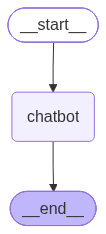

In [30]:
graph

In [22]:
input_data

{'messages': [HumanMessage(content='hi!', additional_kwargs={}, response_metadata={}, id='87a0bd22-89d1-41d6-aac7-f8cd3fe5bdce')]}

In [29]:
for chunk in graph.stream(input_data):
    print(chunk.keys())
    print(chunk['chatbot'].keys())
    print(chunk['chatbot']['messages'])

dict_keys(['chatbot'])
dict_keys(['messages'])
[AIMessage(content='Hello! 👋 How can I help you today?', additional_kwargs={'reasoning_content': 'The user says "hi!" This is a greeting. We should respond with a friendly greeting and maybe ask how we can help.'}, response_metadata={'token_usage': {'completion_tokens': 47, 'prompt_tokens': 73, 'total_tokens': 120, 'completion_time': 0.049700073, 'completion_tokens_details': {'reasoning_tokens': 27}, 'prompt_time': 0.008188611, 'prompt_tokens_details': None, 'queue_time': 0.01649094, 'total_time': 0.057888684}, 'model_name': 'openai/gpt-oss-20b', 'system_fingerprint': 'fp_d3e146e1a5', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a1be59-f53f-763a-a089-d34bb2d87f41-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 73, 'output_tokens': 47, 'total_tokens': 120, 'output_token_details': {'reasoning': 27}})]


In [31]:
[chunk for chunk in graph.stream(input_data)]

[{'chatbot': {'messages': [AIMessage(content='Hello! How can I help you today?', additional_kwargs={'reasoning_content': 'User says "hi!". Simple greeting. Should respond politely.'}, response_metadata={'token_usage': {'completion_tokens': 31, 'prompt_tokens': 73, 'total_tokens': 104, 'completion_time': 0.031625587, 'completion_tokens_details': {'reasoning_tokens': 13}, 'prompt_time': 0.003524835, 'prompt_tokens_details': None, 'queue_time': 0.045299463, 'total_time': 0.035150422}, 'model_name': 'openai/gpt-oss-20b', 'system_fingerprint': 'fp_feb9b278f1', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a1be5c-de83-7651-9eec-47b9c42a96cc-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 73, 'output_tokens': 31, 'total_tokens': 104, 'output_token_details': {'reasoning': 13}})]}}]

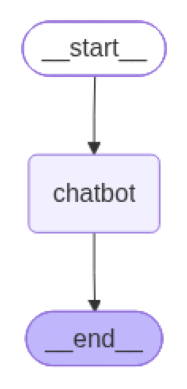

In [33]:
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
from io import BytesIO

# Pygraphviz와 pydot이 필요
!pip install -qU pygraphviz pydot
# Graphviz는 Colab에서는 보통 기본 설치

# Mermaid PNG 이미지를 생성
mermaid_png_bytes = graph.get_graph().draw_mermaid_png()

# Bytes 데이터를 이미지로 로드
img = mpimg.imread(BytesIO(mermaid_png_bytes))

# 이미지를 표시합니다.
plt.imshow(img)
plt.axis('off') # 축을 비활성화
plt.show()

In [36]:
# @title **Adding Memory to StateGraph**

from langgraph.checkpoint.memory import MemorySaver

# Add persistence with MemorySaver
graph = workflow.compile(checkpointer=MemorySaver())

In [37]:
from langgraph.checkpoint.memory import MemorySaver

# Add persistence with MemorySaver
# graph는 실행될 때마다 대화 상대방과의 방 번호(thread_id)별로 State를 자동 저장
graph = builder.compile(checkpointer=MemorySaver())

# Configure thread
# thread_id는 대화방의 '고유 방 번호(구분자)' , thread_id 덕분에 사용자별 / 대화방별로 격리된 독립된 대화 맥락(Context)을 유지
thread1 = {"configurable": {"thread_id": "1"}}

# Run with persistence
result_1 = graph.invoke({"messages": [HumanMessage("hi, my name is Jack!")]}, thread1)
print(result_1)

result_2 = graph.invoke({"messages": [HumanMessage("what is my name?")]}, thread1)
print(result_2)

# Get state
print(graph.get_state(thread1))

{'messages': [HumanMessage(content='hi, my name is Jack!', additional_kwargs={}, response_metadata={}, id='3454a5c2-b374-43fd-93b5-88382e8c7aef'), AIMessage(content='Hi Jack! How can I help you today?', additional_kwargs={'reasoning_content': 'User says "hi, my name is Jack!". We have no constraints. We respond politely.'}, response_metadata={'token_usage': {'completion_tokens': 39, 'prompt_tokens': 78, 'total_tokens': 117, 'completion_time': 0.044326126, 'completion_tokens_details': {'reasoning_tokens': 20}, 'prompt_time': 0.00368043, 'prompt_tokens_details': None, 'queue_time': 0.20993261, 'total_time': 0.048006556}, 'model_name': 'openai/gpt-oss-20b', 'system_fingerprint': 'fp_5979a0e1b7', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a1be5e-767f-75ef-b1e5-e107ee5537bb-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 78, 'output_tokens': 39, 'total_tokens': 117, 'output_token_details': {'reas

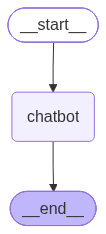

In [38]:
graph

In [39]:
graph.get_state(thread1).metadata

{'source': 'loop', 'step': 4, 'parents': {}}

In [40]:
for message in graph.get_state(thread1).values['messages']:
    print(message.content)

hi, my name is Jack!
Hi Jack! How can I help you today?
what is my name?
Your name is Jack.


# **Modifying Chat History**

In [41]:
# @title **Trimming Messages**

from langchain_core.messages import (
    SystemMessage,
    HumanMessage,
    AIMessage,
    trim_messages,
)

# Define sample messages
messages = [
    SystemMessage(content="you're a good assistant"),
    HumanMessage(content="hi! I'm bob"),
    AIMessage(content="hi!"),
    HumanMessage(content="I like vanilla ice cream"),
    AIMessage(content="nice"),
    HumanMessage(content="whats 2 + 2"),
    AIMessage(content="4"),
    HumanMessage(content="thanks"),
    AIMessage(content="no problem!"),
    HumanMessage(content="having fun?"),
    AIMessage(content="yes!"),
]

# Create trimmer
trimmer = trim_messages(
    max_tokens=65,
    strategy="last",
    token_counter=ChatGroq(model_name="openai/gpt-oss-20b", temperature=0),
    include_system=True,
    allow_partial=False,
    start_on="human",
)

# Apply trimming
trimmed = trimmer.invoke(messages)
print(trimmed)

/usr/local/lib/python3.13/dist-packages/langchain_core/language_models/base.py:463: UserWarning: Using fallback GPT-2 tokenizer for token counting. Token counts may be inaccurate for non-GPT-2 models. For accurate counts, use a model-specific method if available.
  return len(self.get_token_ids(text))


tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.04M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

[SystemMessage(content="you're a good assistant", additional_kwargs={}, response_metadata={}), HumanMessage(content="hi! I'm bob", additional_kwargs={}, response_metadata={}), AIMessage(content='hi!', additional_kwargs={}, response_metadata={}, tool_calls=[], invalid_tool_calls=[]), HumanMessage(content='I like vanilla ice cream', additional_kwargs={}, response_metadata={}), AIMessage(content='nice', additional_kwargs={}, response_metadata={}, tool_calls=[], invalid_tool_calls=[]), HumanMessage(content='whats 2 + 2', additional_kwargs={}, response_metadata={}), AIMessage(content='4', additional_kwargs={}, response_metadata={}, tool_calls=[], invalid_tool_calls=[]), HumanMessage(content='thanks', additional_kwargs={}, response_metadata={}), AIMessage(content='no problem!', additional_kwargs={}, response_metadata={}, tool_calls=[], invalid_tool_calls=[]), HumanMessage(content='having fun?', additional_kwargs={}, response_metadata={}), AIMessage(content='yes!', additional_kwargs={}, respo

In [42]:
for msg in trimmed:
    print(msg.content)

you're a good assistant
hi! I'm bob
hi!
I like vanilla ice cream
nice
whats 2 + 2
4
thanks
no problem!
having fun?
yes!


- max_tokens=25 으로 변경하면 줄어듬
- trim_messages() 의 다른 인자의 기능 확인하라

In [43]:
# Create trimmer
trimmer = trim_messages(
    max_tokens=25,
    strategy="last",
    token_counter=ChatGroq(model_name="llama-3.1-8b-instant", temperature=0),
    include_system=True,
    allow_partial=False,
    start_on="human",
)

# Apply trimming
trimmed = trimmer.invoke(messages)

[msg.content for msg in trimmed]

["you're a good assistant", 'thanks', 'no problem!', 'having fun?', 'yes!']

In [44]:
# @title **Filtering Messages**

from langchain_core.messages import (
 AIMessage,
 HumanMessage,
 SystemMessage,
 filter_messages,
)

messages = [
 SystemMessage("you are a good assistant", id="1"),
 HumanMessage("example input", id="2", name="example_user"),
 AIMessage("example output", id="3", name="example_assistant"),
 HumanMessage("real input", id="4", name="bob"),
 AIMessage("real output", id="5", name="alice"),
]

# 타입이 HumanMessage인 메시지들만 필터링되어 출력
filter_messages(messages, include_types="human")

[HumanMessage(content='example input', additional_kwargs={}, response_metadata={}, name='example_user', id='2'),
 HumanMessage(content='real input', additional_kwargs={}, response_metadata={}, name='bob', id='4')]

In [45]:
filter_messages(messages, exclude_names=["example_user", "example_assistant"])

[SystemMessage(content='you are a good assistant', additional_kwargs={}, response_metadata={}, id='1'),
 HumanMessage(content='real input', additional_kwargs={}, response_metadata={}, name='bob', id='4'),
 AIMessage(content='real output', additional_kwargs={}, response_metadata={}, name='alice', id='5', tool_calls=[], invalid_tool_calls=[])]

In [46]:
filter_messages(
 messages,
 include_types=[HumanMessage, AIMessage],
 exclude_ids=["3"]
)

[HumanMessage(content='example input', additional_kwargs={}, response_metadata={}, name='example_user', id='2'),
 HumanMessage(content='real input', additional_kwargs={}, response_metadata={}, name='bob', id='4'),
 AIMessage(content='real output', additional_kwargs={}, response_metadata={}, name='alice', id='5', tool_calls=[], invalid_tool_calls=[])]

In [47]:
# The filter_messages helper can also be used imperatively or declaratively, making it easy to compose with other components in a chain:

filter_ = filter_messages(exclude_names=["example_user", "example_assistant"])
chain = filter_ | model
chain.invoke(messages)

AIMessage(content='It looks like you might be testing the system. Could you let me know what you’d like to see or do next? I’m here to help!', additional_kwargs={'reasoning_content': 'The user says "real input" and assistant says "real output". This looks like a test or a placeholder. The instruction says "you are a good assistant". So we should respond appropriately. Possibly they want to see a real input? Maybe they want an example? The user just says "real input". Perhaps they want me to produce a real output? The instructions are ambiguous. The user might want an example of real input. Or maybe they want to see a real output for some context. The best response: ask clarifying question? Or provide a simple example. The instruction "you are a good assistant" means we should respond helpfully. So maybe ask what they want. I\'ll ask for clarification.'}, response_metadata={'token_usage': {'completion_tokens': 184, 'prompt_tokens': 89, 'total_tokens': 273, 'completion_time': 0.202591175

In [48]:
# @title **Merging Consecutive Messages**

from langchain_core.messages import (
    AIMessage,
    HumanMessage,
    SystemMessage,
    merge_message_runs,
)

# Sample messages with consecutive messages of same type
messages = [
    SystemMessage(content="you're a good assistant."),
    SystemMessage(content="you always respond with a joke."),
    HumanMessage(
        content=[{"type": "text", "text": "i wonder why it's called langchain"}]
    ),
    HumanMessage(content="and who is harrison chasing anyways"),
    AIMessage(
        content='Well, I guess they thought "WordRope" and "SentenceString" just didn\'t have the same ring to it!'
    ),
    AIMessage(
        content="Why, he's probably chasing after the last cup of coffee in the office!"
    ),
]

# Merge consecutive messages
merged = merge_message_runs(messages)
print(merged)

[SystemMessage(content="you're a good assistant.\nyou always respond with a joke.", additional_kwargs={}, response_metadata={}), HumanMessage(content=[{'type': 'text', 'text': "i wonder why it's called langchain"}, 'and who is harrison chasing anyways'], additional_kwargs={}, response_metadata={}), AIMessage(content='Well, I guess they thought "WordRope" and "SentenceString" just didn\'t have the same ring to it!\nWhy, he\'s probably chasing after the last cup of coffee in the office!', additional_kwargs={}, response_metadata={}, tool_calls=[], invalid_tool_calls=[])]


In [49]:
# HumanMessage 2개와 AIMessage 2개는 실제로 합쳐졌고, SystemMessage는 안 합쳐짐

for msg in merged:
    print(msg.content)

you're a good assistant.
you always respond with a joke.
[{'type': 'text', 'text': "i wonder why it's called langchain"}, 'and who is harrison chasing anyways']
Well, I guess they thought "WordRope" and "SentenceString" just didn't have the same ring to it!
Why, he's probably chasing after the last cup of coffee in the office!


In [50]:
merger = merge_message_runs()
chain = merger | model

In [51]:
chain

RunnableLambda(...)
| ChatGroq(metadata={'lc_versions': {'langchain-core': '1.7.4', 'langchain': '1.4.8'}}, profile={'name': 'GPT OSS 20B', 'release_date': '2025-08-05', 'last_updated': '2026-05-27', 'open_weights': True, 'max_input_tokens': 131072, 'max_output_tokens': 65536, 'text_inputs': True, 'image_inputs': False, 'audio_inputs': False, 'video_inputs': False, 'text_outputs': True, 'image_outputs': False, 'audio_outputs': False, 'video_outputs': False, 'reasoning_output': True, 'tool_calling': True, 'structured_output': True, 'attachment': False, 'temperature': True}, client=<groq.resources.chat.completions.Completions object at 0x7b9cef0bbce0>, async_client=<groq.resources.chat.completions.AsyncCompletions object at 0x7b9cee1e45a0>, model_name='openai/gpt-oss-20b', model_kwargs={}, groq_api_key=SecretStr('**********'))